# Toxic Comment Classification: BiGRU vs BiLSTM

Multi-label classification of toxic comments using the Jigsaw Toxic Comment Classification Challenge dataset.
Each comment can carry any of six labels: `toxic`, `severe_toxic`, `obscene`, `threat`, `insult`, `identity_hate`.

**Contents**
1. Load the data
2. Clean the text
3. Choose the sequence length
4. Tokenize and split
5. Model 1: Bidirectional GRU
6. Model 2: Bidirectional LSTM
7. Compare the models
8. Quick test
9. Export for deployment
10. Experiments log


In [ ]:
import pickle
import re

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Bidirectional, Dense, Dropout, Embedding, GlobalMaxPooling1D, GRU, LSTM
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

## 1. Load the data
Download the dataset from Kaggle and look at the class balance.

In [ ]:
path = kagglehub.dataset_download(
    "julian3833/jigsaw-toxic-comment-classification-challenge"
)
path

Using Colab cache for faster access to the 'jigsaw-toxic-comment-classification-challenge' dataset.


'/kaggle/input/jigsaw-toxic-comment-classification-challenge'

In [ ]:
df = pd.read_csv(path + "/train.csv")
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [ ]:
df["toxic"].value_counts()

,count
toxic,
0,144277
1,15294


## 2. Clean the text
`clean_text` lowercases the text, removes URLs, mentions and IP addresses, expands contractions, undoes symbol disguises such as `a$$`, keeps letters only and shortens repeated letters. The same function is used at prediction time.

In [ ]:
contractions = {
    "you're": "you are",
    "u r": "you are",
    "ur": "your",
    "don't": "do not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "can't": "cannot",
    "won't": "will not",
    "i'm": "i am",
    "it's": "it is",
    "that's": "that is",
    "what's": "what is",
    "they're": "they are",
    "we're": "we are",
    "wasn't": "was not",
    "weren't": "were not",
}


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', '', text)

    # 1. Expand common contractions
    for word, replacement in contractions.items():
        text = re.sub(r'\b' + word + r'\b', replacement, text)

    # 2. Undo symbol disguises inside words (a$$, b!tch)
    text = re.sub(r'(?<=[a-z])@(?=[a-z])', 'a', text)
    text = re.sub(r'(?<=[a-z])\$(?=[a-z\$])', 's', text)
    text = re.sub(r'(?<=[a-z])!(?=[a-z])', 'i', text)
    text = re.sub(r'(?<=[a-z])\*(?=[a-z])', 'u', text)

    # 3. Keep only letters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 4. Shorten repeated letters (stuuuupid -> stuupid)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [ ]:
df['comment_text_clean'] = df['comment_text'].apply(clean_text)

## 3. Choose the sequence length
Check how many cleaned comments fit under different maximum lengths. 200 words covers about 93.6% of comments.

In [ ]:
# 1. Count words per cleaned comment
word_counts = df["comment_text_clean"].str.split().str.len()

# 2. Summary statistics and percentiles
print(
    word_counts.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.98, 0.99])
)

# 3. Check coverage for candidate maxlen values
for m in [100, 150, 200, 250]:
  pct = (word_counts <= m).mean() * 100
  print(f"maxlen = {m:3d}  -->  covers {pct:.2f}% of comments")

count    159571.000000
mean         67.594319
std         100.253678
min           0.000000
50%          36.000000
75%          76.000000
90%         153.000000
95%         231.000000
98%         390.600000
99%         575.000000
max        1403.000000
Name: comment_text_clean, dtype: float64
maxlen = 100  -->  covers 82.21% of comments
maxlen = 150  -->  covers 89.72% of comments
maxlen = 200  -->  covers 93.59% of comments
maxlen = 250  -->  covers 95.67% of comments


## 4. Tokenize and split
Split 80/20, fit the tokenizer on the training split only (30,000 words, `<OOV>` token) and pad every comment to 200 tokens.

In [ ]:
MAX_WORDS = 30000
MAX_LEN = 200

target_cols = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate",
]

In [ ]:
X = df["comment_text_clean"].values
y = df[target_cols].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# 3. Convert texts to padded sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")


X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print("X_train_pad shape:", X_train_pad.shape)
print("X_val_pad shape:", X_test_pad.shape)
print("y_train shape:", y_train.shape)

X_train_pad shape: (127656, 200)
X_val_pad shape: (31915, 200)
y_train shape: (127656, 6)


## 5. Model 1: Bidirectional GRU
Embedding, BiGRU, global max pooling, two dropout layers and a 6-way sigmoid output. Early stopping on validation AUC. The best model is saved as `best_cyberbullying_gru.keras` and the tokenizer as `tokenizer.pkl`.

In [ ]:
EMBEDDING_DIM = 128

model_GRU= Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM),
    Bidirectional(GRU(64, return_sequences=True)),
    GlobalMaxPooling1D(),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(6, activation="sigmoid"),
])


model_GRU.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "binary_accuracy",
        tf.keras.metrics.AUC(name="auc", multi_label=True),
    ],
)

model_GRU.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BATCH_SIZE = 128
EPOCHS = 8

callbacks = [
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=2,
        restore_best_weights=True,
    ),
    ModelCheckpoint(
        "best_cyberbullying_gru.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
    ),
]

history = model_GRU.fit(
    X_train_pad,
    y_train,
    validation_data=(X_test_pad, y_test),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
)

with open("tokenizer.pkl", "wb") as f:
  pickle.dump(tokenizer, f)

print("Training complete. Saved best_cyberbullying_gru.keras and tokenizer.pkl")

Epoch 1/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 38s 28ms/step - auc: 0.9153 - binary_accuracy: 0.9762 - loss: 0.0743 - val_auc: 0.9657 - val_binary_accuracy: 0.9822 - val_loss: 0.0474
Epoch 2/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - auc: 0.9654 - binary_accuracy: 0.9831 - loss: 0.0452 - val_auc: 0.9669 - val_binary_accuracy: 0.9825 - val_loss: 0.0460
Epoch 3/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - auc: 0.9758 - binary_accuracy: 0.9849 - loss: 0.0392 - val_auc: 0.9633 - val_binary_accuracy: 0.9824 - val_loss: 0.0489
Epoch 4/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - auc: 0.9829 - binary_accuracy: 0.9864 - loss: 0.0342 - val_auc: 0.9704 - val_binary_accuracy: 0.9829 - val_loss: 0.0481
Epoch 5/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - auc: 0.9890 - binary_accuracy: 0.9881 - loss: 0.0296 - val_auc: 0.9599 - val_binary_accuracy: 0.9824 - val_loss: 0.0516
Epoch 6/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - auc: 0.9900 - binary_accuracy: 0.9894 - loss: 0.0259 - val_auc: 0.9410

## 6. Model 2: Bidirectional LSTM
Same architecture with an LSTM layer instead of the GRU, trained with the same settings for a fair comparison.

In [ ]:
# 1. Build Multi-label Bidirectional LSTM Model
lstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM),
    Bidirectional(LSTM(64, return_sequences=True)),
    GlobalMaxPooling1D(),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(6, activation="sigmoid"),
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "binary_accuracy",
        tf.keras.metrics.AUC(name="auc", multi_label=True),
    ],
)

lstm_model.summary()

# 2. Callbacks & Training
lstm_callbacks = [
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=2,
        restore_best_weights=True,
    ),
    ModelCheckpoint(
        "best_cyberbullying_lstm.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
    ),
]

lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_test_pad, y_test),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=lstm_callbacks,
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 37s 33ms/step - auc: 0.9044 - binary_accuracy: 0.9748 - loss: 0.0811 - val_auc: 0.9588 - val_binary_accuracy: 0.9815 - val_loss: 0.0506
Epoch 2/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - auc: 0.9625 - binary_accuracy: 0.9821 - loss: 0.0483 - val_auc: 0.9632 - val_binary_accuracy: 0.9819 - val_loss: 0.0482
Epoch 3/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - auc: 0.9736 - binary_accuracy: 0.9838 - loss: 0.0423 - val_auc: 0.9649 - val_binary_accuracy: 0.9823 - val_loss: 0.0483
Epoch 4/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 30s 30ms/step - auc: 0.9774 - binary_accuracy: 0.9850 - loss: 0.0383 - val_auc: 0.9556 - val_binary_accuracy: 0.9821 - val_loss: 0.0500
Epoch 5/8
998/998 ━━━━━━━━━━━━━━━━━━━━ 30s 30ms/step - auc: 0.9824 - binary_accuracy: 0.9862 - loss: 0.0345 - val_auc: 0.9576 - val_binary_accuracy: 0.9819 - val_loss: 0.0540


## 7. Compare the models
Validation AUC and validation loss per epoch for both models.

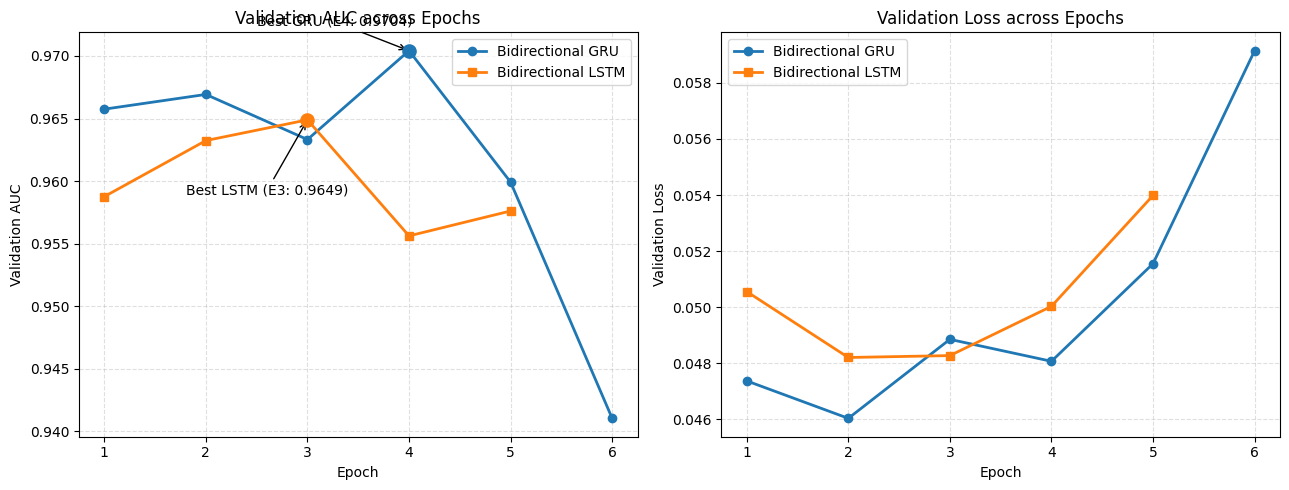

In [ ]:
# Read the validation curves from the training histories
gru_auc = history.history["val_auc"]
gru_loss = history.history["val_loss"]
epochs_gru = np.arange(1, len(gru_auc) + 1)

lstm_auc = lstm_history.history["val_auc"]
lstm_loss = lstm_history.history["val_loss"]
epochs_lstm = np.arange(1, len(lstm_auc) + 1)

# Best epoch of each model by validation AUC
best_gru_idx = int(np.argmax(gru_auc))
best_lstm_idx = int(np.argmax(lstm_auc))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Validation AUC
axes[0].plot(
    epochs_gru, gru_auc, marker="o", linewidth=2, label="Bidirectional GRU"
)
axes[0].plot(
    epochs_lstm, lstm_auc, marker="s", linewidth=2, label="Bidirectional LSTM"
)

axes[0].scatter(
    [epochs_gru[best_gru_idx]], [gru_auc[best_gru_idx]], s=90, zorder=5
)
axes[0].annotate(
    f"Best GRU (E{epochs_gru[best_gru_idx]}: {gru_auc[best_gru_idx]:.4f})",
    xy=(epochs_gru[best_gru_idx], gru_auc[best_gru_idx]),
    xytext=(
        max(1, epochs_gru[best_gru_idx] - 1.5),
        gru_auc[best_gru_idx] + 0.002,
    ),
    arrowprops=dict(arrowstyle="->", lw=1),
)

axes[0].scatter(
    [epochs_lstm[best_lstm_idx]], [lstm_auc[best_lstm_idx]], s=90, zorder=5
)
axes[0].annotate(
    f"Best LSTM (E{epochs_lstm[best_lstm_idx]}: {lstm_auc[best_lstm_idx]:.4f})",
    xy=(epochs_lstm[best_lstm_idx], lstm_auc[best_lstm_idx]),
    xytext=(
        max(1, epochs_lstm[best_lstm_idx] - 1.2),
        lstm_auc[best_lstm_idx] - 0.006,
    ),
    arrowprops=dict(arrowstyle="->", lw=1),
)

axes[0].set_title("Validation AUC across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation AUC")
axes[0].set_xticks(range(1, max(len(epochs_gru), len(epochs_lstm)) + 1))
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# 2. Validation Loss
axes[1].plot(
    epochs_gru, gru_loss, marker="o", linewidth=2, label="Bidirectional GRU"
)
axes[1].plot(
    epochs_lstm, lstm_loss, marker="s", linewidth=2, label="Bidirectional LSTM"
)
axes[1].set_title("Validation Loss across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].set_xticks(range(1, max(len(epochs_gru), len(epochs_lstm)) + 1))
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Quick test
Load the saved GRU model and score two sample sentences. The text goes through `clean_text` first, exactly like during training.

In [ ]:
LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate",
]

model = load_model("best_cyberbullying_gru.keras")
with open("tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

sample_texts = [
    "Thank you so much for helping me with this project!",
    "You are so stupid and nobody likes you.",
]

# Same preprocessing as training: clean first, then tokenize and pad
cleaned = [clean_text(t) for t in sample_texts]
sequences = tokenizer.texts_to_sequences(cleaned)
padded = pad_sequences(sequences, maxlen=MAX_LEN, padding="post", truncating="post")
predictions = model.predict(padded, verbose=0)

for text, probs in zip(sample_texts, predictions):
    print("\nText:", text)
    for label, prob in zip(LABELS, probs):
        print(f"  {label}: {prob:.4f}")


Text: Thank you so much for helping me with this project!
  toxic: 0.0001
  severe_toxic: 0.0000
  obscene: 0.0000
  threat: 0.0000
  insult: 0.0000
  identity_hate: 0.0000

Text: You are so stupid and nobody likes you.
  toxic: 0.9915
  severe_toxic: 0.1271
  obscene: 0.6279
  threat: 0.0352
  insult: 0.8542
  identity_hate: 0.1042


## 9. Export for deployment
Save a slim copy of the GRU model (no optimizer state) as `model.keras` and download it together with `tokenizer.pkl`.

In [ ]:
from google.colab import files

slim = load_model("best_cyberbullying_gru.keras", compile=False)
slim.save("model.keras")

files.download("model.keras")
files.download("tokenizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Experiments log

Runs that were actually done in this notebook.

| Version | What changed | Result |
|---|---|---|
| v1 | Bidirectional GRU, 30,000 words, max length 200, text cleaned with `clean_text` | Best validation AUC 0.9704 (epoch 4) |
| v2 | Same setup with a Bidirectional LSTM instead of the GRU | Best validation AUC 0.9649 (epoch 3) |